## Pregunta 1


Antes de cualquier cosa implementaré las librerias necesarias


In [5]:
%pip install rawpy

   ---------------------------------------- 0.0/921.1 kB ? eta -:--:--
   ---------------------------------------- 921.1/921.1 kB 31.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg


importo la imagen y la paso a escala de grises

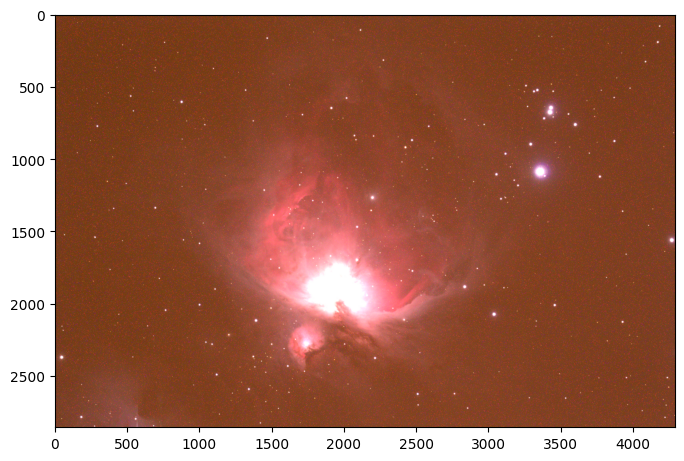

In [10]:
import matplotlib.pyplot as plt
import rawpy

#archivo RAW
with rawpy.imread('P1.CR2') as raw:
  imagen_rgb = raw.postprocess()
plt.figure(figsize=(8, 6))
plt.imshow(imagen_rgb)
plt.show()

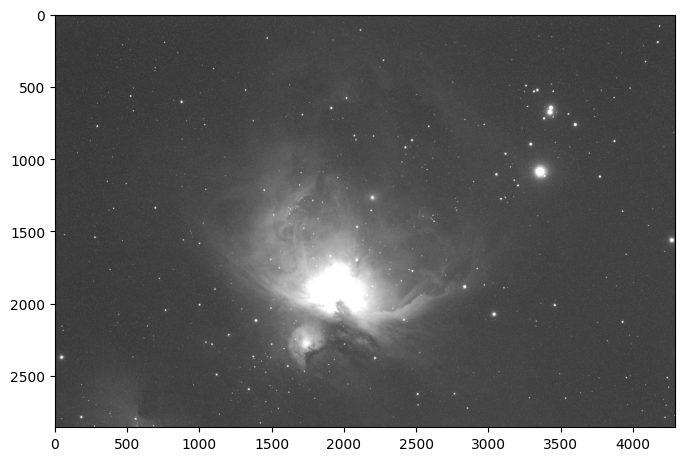

In [15]:
import cv2

img = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(8, 6))
plt.imshow(img, cmap='gray')
plt.show()

Lo primero que se pide es el padding configurable, así que ocupo una función de numpy que hace lo siguiente: recibe la imagen, alto y ancho para armar la nueva, además deja elegor el modo en el que se va a expandir:

reflect refleja los pixeles internos para rellenar el borde, constant lo llena con ceros y edge repite el valor del pixel más cercano al borde

In [29]:
def padding(imagen, Alto, Ancho, modo="reflect"):
  return np.pad( imagen, ((Alto, Alto), (Ancho, Ancho)), mode=modo,)

Ahora voy con la aplicación de la FFT 2D, donde se aplica directamente con numpy y luego la shifteo para que la frecuencia cero quede al centro

In [30]:
def calcularFFT(imagen):
  espectro = np.fft.fft2(imagen)
  espectrofinal = np.fft.fftshift(espectro)
  return espectrofinal

Como la imagen se agranda con los bordes la puedo devolver a su tamaño original con una funcion para recortar

In [36]:
def recortar(imagenPad, alto, ancho, paddingAlto, paddingAncho):
  return imagenPad[paddingAlto : paddingAlto + alto, paddingAncho : paddingAncho + ancho]

Y también se pide la transformada inversa que seria lo siguiente:

In [33]:
def calcularIFFT(espectrofinal):
  espectro = np.fft.ifftshift(espectrofinal)
  return np.abs(np.fft.ifft2(espectro))

Ahora si paso al filtro notch

Para poder construir el filtro ideal se deben conocer las coordenadas centradas del espectro, ademas en vez de llenar la matriz de 0, en un inicio dejaré pasar la mayoria de frecuencias llenándolas con 1.  Luego, a partir de los centros se calcula la distancia hacia las zonas ruidosas y se les pone un 0 para bloquear el ruido de manera directa

In [53]:
def crearfiltronotchideal(forma, parejacentros, radios):
  filas, columnas = forma
  #con esto establezco las coordenadas centradas
  u = np.arange(filas) - filas // 2
  v = np.arange(columnas) - columnas // 2
  # por recomendacion de la IA ocuparpe meshgrid
  # que pasa vectores a matrices 2D para ubicar cada píxel en la cuadrícula simultáneamente
  U, V = np.meshgrid(u, v, indexing="ij")

  # dejo pasar las frecuencias
  filtro = np.ones(forma, dtype=np.float32)

  #revisa los pares de centros y radios para
  #bloquear múltiples frecuencias de ruido periódico
  for i in range(len(parejacentros)):
    centro = parejacentros[i]
    radio = radios[i]
    rfila, rcolumna = centro

    #distancias a los pares simetricos (+u0, +v0) y (-u0, -v0)
    dist1 = np.sqrt((U - rfila) ** 2 + (V - rcolumna) ** 2)
    dist2 = np.sqrt((U + rfila) ** 2 + (V + rcolumna) ** 2)
    #condiciones de distancia para detectar el ruido en ambos centros simétricos
    zonasruido = np.logical_or(dist1 <= radio, dist2 <= radio)
    filtro[zonasruido] = 0

  return filtro

Acá también se parte cconfigurando las coordenadas iniciales, pero luego se calculas las distancias al cuadrado para aplicar la función en dorma de campana invertida, asi atenuando el ruido suabemente en vez de hacer cortes

In [55]:
def crearfiltronotchgaussiano(forma, parejacentros, desviaciones):
  filas, columnas = forma
  u = np.arange(filas) - filas // 2
  v = np.arange(columnas) - columnas // 2
  U, V = np.meshgrid(u, v, indexing="ij")
  filtro = np.ones(forma, dtype=np.float32)
  for i in range(len(parejacentros)):
    centro = parejacentros[i]
    desviacion = desviaciones[i]
    rfila, rcolumna = centro

    #la distancia al cuadrado para ajustarse a la campana de gauss
    dist1cuadrada = (U - rfila) ** 2 + (V - rcolumna) ** 2
    dist2cuadrada = (U + rfila) ** 2 + (V + rcolumna) ** 2

    #campana gaussiana invertida: 1 - exp(-D^2 / (2 * sigma^2))
    val1 = 1.0 - np.exp(-dist1cuadrada / (2.0 * (desviacion ** 2)))
    val2 = 1.0 - np.exp(-dist2cuadrada / (2.0 * (desviacion ** 2)))

    #aplicar multiples filtros notch
    filtro *= val1 * val2

  return filtro

In [57]:
def procesonotchideal( imagenoriginal, altoextendido, anchoextendido, parejacentros, radios, modo):
  #busco las dimensiones originales
  altooriginal, anchooriginal = imagenoriginal.shape

  #padding para la imagen
  imagenpad = padding(imagenoriginal, altoextendido, anchoextendido, modo)

  #calculo de la FFT 2D 
  espectrocomplejo = calcularfft(imagenpad)

  #aplico notch ideal
  filtronotch = crearfiltronotchideal(espectrocomplejo.shape, parejacentros, radios)

  # se multiplica espectro por la funcion de transferencia del filtro
  espectrofiltrado = espectrocomplejo * filtronotch

  # transformada inversa para volver al dominio que queremos
  imagenreconstruidapad = calcularifft(espectrofiltrado)

  #volvemos al tamaño original
  resultadofinal = recortar(
      imagenreconstruidapad,
      altooriginal,
      anchooriginal,
      altoextendido,
      anchoextendido,
  )

  return resultadofinal

In [58]:
def procesonotchgaussiano(
    imagenoriginal, altoextendido, anchoextendido, parejacentros, desviaciones, modo
):
  # busco las dimensiones originales
  altooriginal, anchooriginal = imagenoriginal.shape

  # padding para la imagen
  imagenpad = padding(imagenoriginal, altoextendido, anchoextendido, modo)

  # calculo de la FFT 2D
  espectrocomplejo = calcularfft(imagenpad)

  # aplico notch gaussiano
  filtronotch = crearfiltronotchgaussiano(
      espectrocomplejo.shape, parejacentros, desviaciones
  )

  # se multiplica espectro por la funcion de transferencia del filtro
  espectrofiltrado = espectrocomplejo * filtronotch

  # transformada inversa para volver al dominio que queremos
  imagenreconstruidapad = calcularifft(espectrofiltrado)

  # volvemos al tamaño original
  resultadofinal = recortar(
      imagenreconstruidapad,
      altooriginal,
      anchooriginal,
      altoextendido,
      anchoextendido,
  )

  return resultadofinal

Esta es la parte de experimentación y análisis

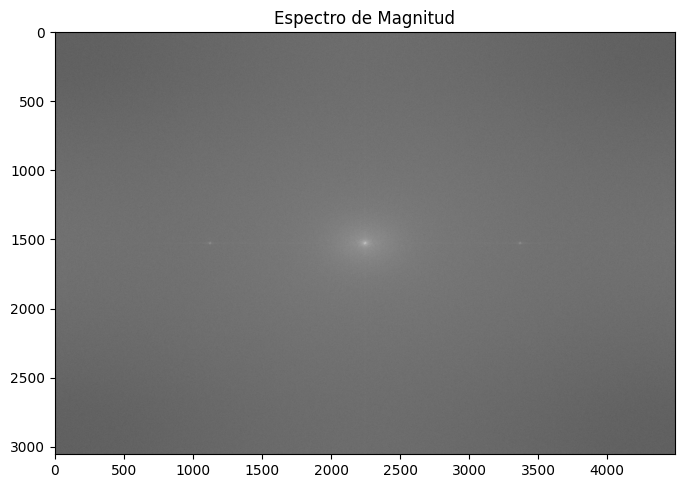

In [79]:
#espectro de magnitud de la imagen
#defino cuanto padding quiero
altoext = 100
anchoext = 100
imagenpad = padding(img, altoext, anchoext, modo="reflect")
espectrocomplejo = calcularFFT(imagenpad)
espectromagnitud = np.log(1 + np.abs(espectrocomplejo))

plt.figure(figsize=(8, 6))
plt.imshow(espectromagnitud, cmap="gray")
plt.title("Espectro de Magnitud")
plt.show()

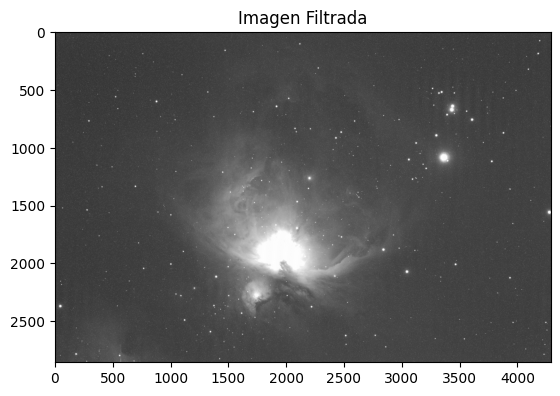

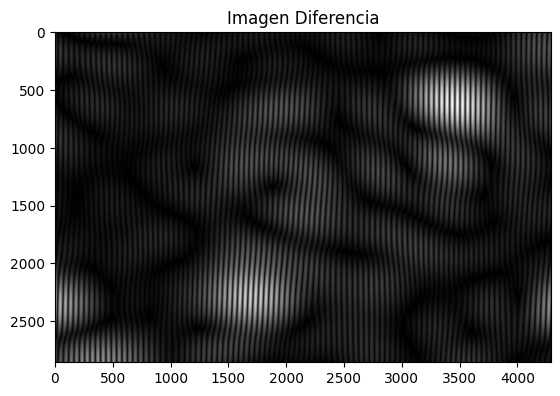

In [71]:
# Probar un radio simple y mostrar la imagen filtrada y su diferencia
radio = 5
filtroideal = crearfiltronotchideal(espectrocomplejo.shape, [(0, 50)], [radio])
imgfiltrada = recortar(
    calcularIFFT(espectrocomplejo * filtroideal),
    altoorig,
    anchoorig,
    altoext,
    anchoext,
)
imagendiferencia = np.abs(img - imgfiltrada)

plt.imshow(imgfiltrada, cmap="gray")
plt.title("Imagen Filtrada")
plt.show()

plt.imshow(imagendiferencia, cmap="gray")
plt.title("Imagen Diferencia")
plt.show()

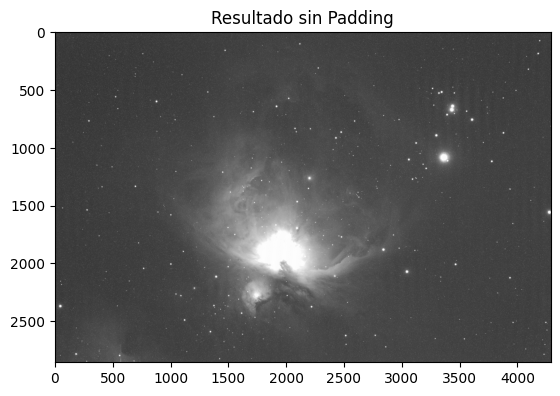

In [74]:
# Aplicar el filtro directamente a la imagen sin extenderla (sin padding)
espectrosin = calcularFFT(img)
filtromenos = crearfiltronotchideal(espectrosin.shape, [(0, 50)], [5])
imagensin = calcularIFFT(espectrosin * filtromenos)

plt.imshow(imagensin, cmap="gray")
plt.title("Resultado sin Padding")
plt.show()

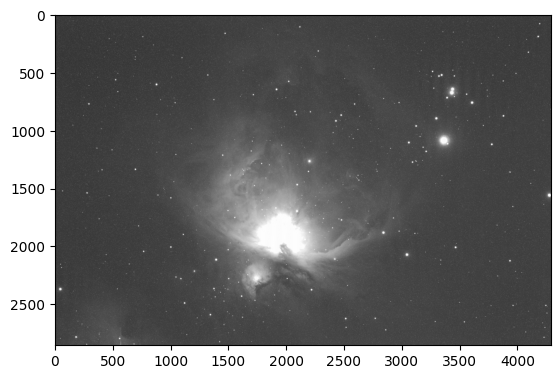

In [78]:
# Aplicar la opción final (Filtro Gaussiano con la desviación elegida)
desviacion = 4.0
filtrofinal = crearfiltronotchgaussiano(
    espectrocomplejo.shape, [(0, 50)], [desviacion]
)
imagenfinal = recortar(
    calcularIFFT(espectrocomplejo * filtrofinal),
    altoorig,
    anchoorig,
    altoext,
    anchoext,
)

plt.imshow(imagenfinal, cmap="gray")
plt.show()